# Import packages and data

In [1]:
from pathlib import Path
import duckdb
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error


# Find the course repository
root = next(
    p for p in [Path.cwd(), *Path.cwd().parents]
    if (p / "Lectures/modeling/data").is_dir()
)

# Connect to the homework database
db_path = root / "Lectures/modeling/data/equities_top2000.duckdb"

assert db_path.is_file(), f"Database not found: {db_path}"

conn = duckdb.connect(str(db_path), read_only=True)

In [2]:
#  tables
display(conn.execute("SHOW TABLES").df()) # shows all the tables within the database

#  available price history
display(conn.execute("""
    SELECT MIN(date) AS first_date,
           MAX(date) AS last_date,
           COUNT(*) AS observations
    FROM prices
""").df())

,name
0,benchmark
1,calendar
2,dataset_metadata
3,dividends
4,fundamentals
5,prices
6,universe
7,universe_candidates
8,universe_membership
9,universe_rebalances


,first_date,last_date,observations
0,2000-01-03,2026-09-30,15839788


In [3]:
# first date and last date line up with instructions

In [4]:

for table in ["prices", "universe_membership", "benchmark"]:
    print(f"\n{table.upper()}")
    display(conn.execute(f"DESCRIBE {table}").df())

# prices table contains historical stock prices
# universe_membership shows stocks eligible for purchase in each quarter
# benchmark is SP500 return data used for final comparison


PRICES


,column_name,column_type,null,key,default,extra
0,symbol,VARCHAR,YES,None,None,None
1,date,DATE,YES,None,None,None
2,open,DOUBLE,YES,None,None,None
3,high,DOUBLE,YES,None,None,None
4,low,DOUBLE,YES,None,None,None
5,close,DOUBLE,YES,None,None,None
6,adj_close,DOUBLE,YES,None,None,None
7,volume,BIGINT,YES,None,None,None
8,source,VARCHAR,YES,None,None,None



UNIVERSE_MEMBERSHIP


,column_name,column_type,null,key,default,extra
0,quarter_start,DATE,YES,None,None,None
1,quarter_end,DATE,YES,None,None,None
2,selection_date,DATE,YES,None,None,None
3,effective_start,DATE,YES,None,None,None
4,symbol,VARCHAR,YES,None,None,None
5,selection_close,DOUBLE,YES,None,None,None
6,shares_fiscal_date,DATE,YES,None,None,None
7,shares_filing_date,DATE,YES,None,None,None
8,shares_available_date,DATE,YES,None,None,None
9,selection_shares,DOUBLE,YES,None,None,None



BENCHMARK


,column_name,column_type,null,key,default,extra
0,symbol,VARCHAR,YES,None,None,None
1,date,DATE,YES,None,None,None
2,close,DOUBLE,YES,None,None,None
3,adj_close,DOUBLE,YES,None,None,None
4,source,VARCHAR,YES,None,None,None


# Feature Engineering

First feature: momentum
Momentum measures how much a stock has increased or decreased over a previous period
Strategy: stocks with historically high momentum will contunue performing well
Assuming 252 trading days, I'm using 63 day momentum (3 months)

Using Apple as an example to get an idea of how momentum works

In [5]:
# Load Apple's historical prices as an example
apple_prices = conn.execute("""
    SELECT c.date, p.adj_close
    FROM calendar c
    LEFT JOIN prices p
        ON c.date = p.date AND p.symbol = 'AAPL'
    WHERE c.date BETWEEN '2009-01-01' AND '2010-12-31'
    ORDER BY c.date
""").df()

In [6]:
# check to see if there are any invalid prices
apple_prices[apple_prices["adj_close"]<=0]

,date,adj_close


In [7]:
# set any negative prices to NaN
apple_prices.loc[apple_prices["adj_close"] <= 0, "adj_close"] = np.nan

# calc daily returns
apple_prices["daily_return"] = apple_prices["adj_close"].pct_change(fill_method=None)

# calc 63 day momentum
apple_prices["momentum_63d"] = apple_prices["adj_close"] / apple_prices["adj_close"].shift(63) - 1

# check to ensure there is 63 consecutive daily returns before looking at momentum values
apple_prices.loc[
    apple_prices["daily_return"].rolling(63).count() < 63, # counts how many daily returns over past 63 days are not missing
    "momentum_63d" 
] = np.nan # if any obvervations have less than 63 returns, set them to NaN

apple_prices.tail(10)

,date,adj_close,daily_return,momentum_63d
494,2010-12-17,9.60,-0.002079,0.132075
495,2010-12-20,9.65,0.005208,0.136631
496,2010-12-21,9.71,0.006218,0.126450
497,2010-12-22,9.73,0.002060,0.124855
498,2010-12-23,9.69,-0.004111,0.107429
499,2010-12-27,9.72,0.003096,0.114679
500,2010-12-28,9.74,0.002058,0.135198
501,2010-12-29,9.74,0.000000,0.132558
502,2010-12-30,9.69,-0.005133,0.141343
503,2010-12-31,9.66,-0.003096,0.141844


Next feature: historical volatility (21 day, 1 month)
measures how much a stock's daily returns fluctuate 

In [8]:
apple_prices["volatility_21d"] = (apple_prices["daily_return"].rolling(21).std() * np.sqrt(252))

apple_prices.tail(10)

,date,adj_close,daily_return,momentum_63d,volatility_21d
494,2010-12-17,9.60,-0.002079,0.132075,0.179924
495,2010-12-20,9.65,0.005208,0.136631,0.156468
496,2010-12-21,9.71,0.006218,0.126450,0.153829
497,2010-12-22,9.73,0.002060,0.124855,0.137315
498,2010-12-23,9.69,-0.004111,0.107429,0.127096
499,2010-12-27,9.72,0.003096,0.114679,0.112885
500,2010-12-28,9.74,0.002058,0.135198,0.112472
501,2010-12-29,9.74,0.000000,0.132558,0.112385
502,2010-12-30,9.69,-0.005133,0.141343,0.088737
503,2010-12-31,9.66,-0.003096,0.141844,0.070774


next feautre: market beta
beta measures stock's sensitivity to movements in market

In [9]:
# load S&P 500 historical prices
market = conn.execute("""
    SELECT date, adj_close AS market_close
    FROM benchmark
    WHERE symbol = '^SP500TR'
    ORDER BY date
""").df()


In [10]:
market

,date,market_close
0,2000-01-03,2002.11
1,2000-01-04,1925.41
2,2000-01-05,1929.28
3,2000-01-06,1931.51
4,2000-01-07,1983.83
...,...,...
6721,2026-09-24,17276.46
6722,2026-09-25,17364.79
6723,2026-09-28,17230.95
6724,2026-09-29,17202.12


In [11]:
#merge apple table with market table via date
apple_prices = apple_prices.merge(market,on="date",how="left")

In [12]:
apple_prices.tail()

,date,adj_close,daily_return,momentum_63d,volatility_21d,market_close
499,2010-12-27,9.72,0.003096,0.114679,0.112885,2113.67
500,2010-12-28,9.74,0.002058,0.135198,0.112472,2115.32
501,2010-12-29,9.74,0.000000,0.132558,0.112385,2117.83
502,2010-12-30,9.69,-0.005133,0.141343,0.088737,2114.70
503,2010-12-31,9.66,-0.003096,0.141844,0.070774,2114.29


In [13]:
# calc daily market returns
apple_prices["market_return"] = (apple_prices["market_close"].pct_change(fill_method=None))

In [14]:
# calc 126-day market beta (6 month)
# beta = cov( return on stock, return on market) / var( return on market)

apple_prices["beta_126d"] = (
    apple_prices["daily_return"].rolling(126).cov(apple_prices["market_return"]) /
    apple_prices["market_return"].rolling(126).var())

In [15]:
apple_prices

,date,adj_close,daily_return,momentum_63d,volatility_21d,market_close,market_return,beta_126d
0,2009-01-02,2.72,NaN,NaN,NaN,1499.17,NaN,NaN
1,2009-01-05,2.83,0.040441,NaN,NaN,1492.21,-0.004643,NaN
2,2009-01-06,2.78,-0.017668,NaN,NaN,1503.87,0.007814,NaN
3,2009-01-07,2.72,-0.021583,NaN,NaN,1459.58,-0.029451,NaN
4,2009-01-08,2.77,0.018382,NaN,NaN,1464.60,0.003439,NaN
...,...,...,...,...,...,...,...,...
499,2010-12-27,9.72,0.003096,0.114679,0.112885,2113.67,0.000615,0.956028
500,2010-12-28,9.74,0.002058,0.135198,0.112472,2115.32,0.000781,0.913236
501,2010-12-29,9.74,0.000000,0.132558,0.112385,2117.83,0.001187,0.903677
502,2010-12-30,9.69,-0.005133,0.141343,0.088737,2114.70,-0.001478,0.900819


Next feature: max drawdown (63 days, 3 months)
calculates the largest decline over past 63 days

In [16]:
def max_drawdown(prices):
    peak = np.maximum.accumulate(prices) # tracks the highest price so far
    drawdown = prices / peak - 1 # for each day, calculates % change from the highest price so far
    return drawdown.min() # returns the lowest % change, aka the max drawdown

apple_prices["max_drawdown_63d"] = (
    apple_prices["adj_close"].rolling(64).apply(max_drawdown, raw=True) # uses rolling to go over past 63 days
)

In [17]:
apple_prices

,date,adj_close,daily_return,momentum_63d,volatility_21d,market_close,market_return,beta_126d,max_drawdown_63d
0,2009-01-02,2.72,NaN,NaN,NaN,1499.17,NaN,NaN,NaN
1,2009-01-05,2.83,0.040441,NaN,NaN,1492.21,-0.004643,NaN,NaN
2,2009-01-06,2.78,-0.017668,NaN,NaN,1503.87,0.007814,NaN,NaN
3,2009-01-07,2.72,-0.021583,NaN,NaN,1459.58,-0.029451,NaN,NaN
4,2009-01-08,2.77,0.018382,NaN,NaN,1464.60,0.003439,NaN,NaN
...,...,...,...,...,...,...,...,...,...
499,2010-12-27,9.72,0.003096,0.114679,0.112885,2113.67,0.000615,0.956028,-0.057652
500,2010-12-28,9.74,0.002058,0.135198,0.112472,2115.32,0.000781,0.913236,-0.057652
501,2010-12-29,9.74,0.000000,0.132558,0.112385,2117.83,0.001187,0.903677,-0.057652
502,2010-12-30,9.69,-0.005133,0.141343,0.088737,2114.70,-0.001478,0.900819,-0.057652


Final feature: 63 day relative momentum
measures how much stock has outperformed/underperformed the SP 500 over previous 63 days (3 months)

In [18]:
# first calculate market momentum over 63 days
apple_prices["market_momentum_63d"] = (
    apple_prices["market_close"] /
    apple_prices["market_close"].shift(63) - 1)

In [19]:
# check
apple_prices.loc[
    apple_prices["market_return"].rolling(63).count() < 63,
    "market_momentum_63d"] = np.nan

# calc relative momentum (just the difference between the 2 momentums)
apple_prices["relative_momentum_63d"] = (
    apple_prices["momentum_63d"] -
    apple_prices["market_momentum_63d"])

In [20]:
apple_prices

,date,adj_close,daily_return,momentum_63d,volatility_21d,market_close,market_return,beta_126d,max_drawdown_63d,market_momentum_63d,relative_momentum_63d
0,2009-01-02,2.72,NaN,NaN,NaN,1499.17,NaN,NaN,NaN,NaN,NaN
1,2009-01-05,2.83,0.040441,NaN,NaN,1492.21,-0.004643,NaN,NaN,NaN,NaN
2,2009-01-06,2.78,-0.017668,NaN,NaN,1503.87,0.007814,NaN,NaN,NaN,NaN
3,2009-01-07,2.72,-0.021583,NaN,NaN,1459.58,-0.029451,NaN,NaN,NaN,NaN
4,2009-01-08,2.77,0.018382,NaN,NaN,1464.60,0.003439,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...
499,2010-12-27,9.72,0.003096,0.114679,0.112885,2113.67,0.000615,0.956028,-0.057652,0.106645,0.008034
500,2010-12-28,9.74,0.002058,0.135198,0.112472,2115.32,0.000781,0.913236,-0.057652,0.101964,0.033234
501,2010-12-29,9.74,0.000000,0.132558,0.112385,2117.83,0.001187,0.903677,-0.057652,0.106009,0.026549
502,2010-12-30,9.69,-0.005133,0.141343,0.088737,2114.70,-0.001478,0.900819,-0.057652,0.107782,0.033561


Test code with only 10 stocks to find any bugs, then after checking all code I'll add in all the stocks to run the program

In [21]:
# Select 10 stocks from  2010-Q1
stocks = conn.execute("""
    SELECT symbol
    FROM universe_membership
    WHERE quarter_start = '2010-01-01'
    ORDER BY universe_rank
    LIMIT 10
""").df()["symbol"].tolist() # take 10 highest universe_ranked stocks

print(stocks)

['TSYS', 'APDN', 'XOM', 'PEGY', 'MSFT', 'BKNG', 'WMT', 'CCZ', 'AAPL', 'PG']


In [22]:
stock_prices = conn.execute("""
    SELECT s.symbol, c.date, p.adj_close
    FROM calendar c
    CROSS JOIN (SELECT UNNEST(?) AS symbol) s
    LEFT JOIN prices p
        ON p.date = c.date AND p.symbol = s.symbol
    WHERE c.date BETWEEN '2008-01-01' AND '2015-12-31'
    ORDER BY s.symbol, c.date
""", [stocks]).df()

display(stock_prices.head(10))

,symbol,date,adj_close
0,AAPL,2008-01-02,5.83
1,AAPL,2008-01-03,5.83
2,AAPL,2008-01-04,5.39
3,AAPL,2008-01-07,5.31
4,AAPL,2008-01-08,5.13
5,AAPL,2008-01-09,5.37
6,AAPL,2008-01-10,5.33
7,AAPL,2008-01-11,5.17
8,AAPL,2008-01-14,5.35
9,AAPL,2008-01-15,5.06


In [23]:
print("count of stocks:", stock_prices["symbol"].nunique())
print("count of observations:", len(stock_prices))


count of stocks: 10
count of observations: 20150


In [24]:
# sum any missing prices - should all equal zero
stock_prices["adj_close"].isna().groupby(stock_prices["symbol"]).sum()

symbol
AAPL       0
APDN       0
BKNG       0
CCZ     1164
MSFT       0
PEGY       0
PG         0
TSYS       0
WMT        0
XOM        0
Name: adj_close, dtype: int64

Now I'm going to run the five features for all 10 stocks to test to make sure the code can be applied to the entire database

In [25]:
# first add market data to stocks, need SP 500 prices to calculate beta and relative momentum
#this is the same idea as what I did for Apple

# merge market prices with  stock data
stock_prices = stock_prices.merge(market[["date", "market_close"]],on="date",how="left")

In [26]:
stock_prices

,symbol,date,adj_close,market_close
0,AAPL,2008-01-02,5.83,2273.41
1,AAPL,2008-01-03,5.83,2273.41
2,AAPL,2008-01-04,5.39,2217.59
3,AAPL,2008-01-07,5.31,2224.76
4,AAPL,2008-01-08,5.13,2184.67
...,...,...,...,...
20145,XOM,2015-12-24,53.07,3852.31
20146,XOM,2015-12-28,52.68,3843.94
20147,XOM,2015-12-29,52.96,3885.55
20148,XOM,2015-12-30,52.25,3857.90


In [27]:
# function to calculate max drawdown
def max_drawdown(prices):
    peak = np.maximum.accumulate(prices)
    drawdown = prices / peak - 1
    return drawdown.min()


# function to calculate features for each stock
def calculate_features(df):
    df = df.sort_values("date").copy()

    # calc daily stock and market returns
    df["daily_return"] = df["adj_close"].pct_change(fill_method=None)
    df["market_return"] = df["market_close"].pct_change(fill_method=None)

    # calc 63 day momentum
    df["momentum_63d"] = df["adj_close"] / df["adj_close"].shift(63) - 1

    # check there are 63 consecutive valid returns
    df.loc[
        df["daily_return"].rolling(63).count() < 63,
        "momentum_63d"
    ] = np.nan

    # calc 21 day annualized volatility
    df["volatility_21d"] = df["daily_return"].rolling(21).std() * np.sqrt(252)

    # calc 126 day beta
    df["beta_126d"] = (
        df["daily_return"].rolling(126).cov(df["market_return"]) /
        df["market_return"].rolling(126).var() )

 

    # calc 63 day max drawdown
    df["max_drawdown_63d"] = (
        df["adj_close"].rolling(64).apply(max_drawdown, raw=True)
    )

    # calc 63 day market momentum
    df["market_momentum_63d"] = (
        df["market_close"] / df["market_close"].shift(63) - 1
    )

    # ensure there are 63 consecutive valid market returns
    df.loc[
        df["market_return"].rolling(63).count() < 63,
        "market_momentum_63d"
    ] = np.nan

    # calc relative momentum
    df["relative_momentum_63d"] = (
        df["momentum_63d"] - df["market_momentum_63d"]
    )

    return df

In [28]:
# apply feature calculations to each stock separately

results = []

# calculate features for each stock separately
for symbol, df in stock_prices.groupby("symbol"):
    stock = calculate_features(df)
    results.append(stock)

# combine all stocks into one dataframe
stock_features = pd.concat(results, ignore_index=True)

In [29]:
stock_features

,symbol,date,adj_close,market_close,daily_return,market_return,momentum_63d,volatility_21d,beta_126d,max_drawdown_63d,market_momentum_63d,relative_momentum_63d
0,AAPL,2008-01-02,5.83,2273.41,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,AAPL,2008-01-03,5.83,2273.41,0.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN
2,AAPL,2008-01-04,5.39,2217.59,-0.075472,-0.024553,NaN,NaN,NaN,NaN,NaN,NaN
3,AAPL,2008-01-07,5.31,2224.76,-0.014842,0.003233,NaN,NaN,NaN,NaN,NaN,NaN
4,AAPL,2008-01-08,5.13,2184.67,-0.033898,-0.018020,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...
20145,XOM,2015-12-24,53.07,3852.31,-0.010811,-0.001596,0.092650,0.300014,1.113116,-0.136632,0.073154,0.019496
20146,XOM,2015-12-28,52.68,3843.94,-0.007349,-0.002173,0.094081,0.299932,1.127749,-0.136632,0.098705,-0.004624
20147,XOM,2015-12-29,52.96,3885.55,0.005315,0.010825,0.094441,0.300805,1.123212,-0.136632,0.109165,-0.014724
20148,XOM,2015-12-30,52.25,3857.90,-0.013406,-0.007116,0.059623,0.302788,1.133079,-0.136632,0.080593,-0.020970


Have all 10 stocks with relevant features, now going to use regression

For each stock, need 3 dates:
1. signal date: when to calculate the features
2. entry date: the next trading period
3. exit date: the first trading day after the 90 days from entry

Ex. signal on march 31, 2016 will produce entry date on 4/1/2016 to schedule an exit on june 30, 2016

In [30]:
# load trading calendar (including dates needed for future returns)
sessions = conn.execute("""
    SELECT date
    FROM calendar
    WHERE date BETWEEN '2008-01-01' AND '2016-04-30'
    ORDER BY date
""").df()


In [31]:
sessions

,date
0,2008-01-02
1,2008-01-03
2,2008-01-04
3,2008-01-07
4,2008-01-08
...,...
2092,2016-04-25
2093,2016-04-26
2094,2016-04-27
2095,2016-04-28


In [32]:

# entry is the next trading session
sessions["entry_date"] = sessions["date"].shift(-1)

# maturity is 90 calendar days after entry
sessions["maturity_date"] = (
    sessions["entry_date"] + pd.Timedelta(days=90)
)

# find the first market session on or after maturity
exit_dates = sessions[["date"]].rename(columns={"date": "exit_date"})

schedule = pd.merge_asof(
    sessions.dropna(subset=["maturity_date"]).sort_values("maturity_date"),
    exit_dates,
    left_on="maturity_date",
    right_on="exit_date",
    direction="forward"
)

# merge dates with our stock features
stock_features = stock_features.merge(
    schedule[["date", "entry_date", "maturity_date", "exit_date"]],
    on="date",
    how="left"
)

stock_features[["symbol", "date", "entry_date", "exit_date"]].tail()

,symbol,date,entry_date,exit_date
20145,XOM,2015-12-24,2015-12-28,2016-03-28
20146,XOM,2015-12-28,2015-12-29,2016-03-28
20147,XOM,2015-12-29,2015-12-30,2016-03-29
20148,XOM,2015-12-30,2015-12-31,2016-03-30
20149,XOM,2015-12-31,2016-01-04,2016-04-04


In [33]:
stock_features.tail()

,symbol,date,adj_close,market_close,daily_return,market_return,momentum_63d,volatility_21d,beta_126d,max_drawdown_63d,market_momentum_63d,relative_momentum_63d,entry_date,maturity_date,exit_date
20145,XOM,2015-12-24,53.07,3852.31,-0.010811,-0.001596,0.092650,0.300014,1.113116,-0.136632,0.073154,0.019496,2015-12-28,2016-03-27,2016-03-28
20146,XOM,2015-12-28,52.68,3843.94,-0.007349,-0.002173,0.094081,0.299932,1.127749,-0.136632,0.098705,-0.004624,2015-12-29,2016-03-28,2016-03-28
20147,XOM,2015-12-29,52.96,3885.55,0.005315,0.010825,0.094441,0.300805,1.123212,-0.136632,0.109165,-0.014724,2015-12-30,2016-03-29,2016-03-29
20148,XOM,2015-12-30,52.25,3857.90,-0.013406,-0.007116,0.059623,0.302788,1.133079,-0.136632,0.080593,-0.020970,2015-12-31,2016-03-30,2016-03-30
20149,XOM,2015-12-31,52.15,3821.60,-0.001914,-0.009409,0.061686,0.302308,1.128165,-0.136632,0.068241,-0.006555,2016-01-04,2016-04-03,2016-04-04


Entry and exit dates are generated for each stock and trading day.
Now need stock prices on its entry date, exit date, and find the return over that period

In [34]:
# load prices for 10 stocks, including 2016 for future exits
quotes = conn.execute("""
    SELECT symbol, date, adj_close
    FROM prices
    WHERE date BETWEEN '2008-01-01' AND '2016-04-30'
    AND symbol IN (SELECT UNNEST(?))
""", [stocks]).df()

In [35]:
quotes

,symbol,date,adj_close
0,AAPL,2008-01-02,5.83
1,AAPL,2008-01-03,5.83
2,AAPL,2008-01-04,5.39
3,AAPL,2008-01-07,5.31
4,AAPL,2008-01-08,5.13
...,...,...,...
19690,APDN,2016-04-25,1839000.00
19691,APDN,2016-04-26,1818000.00
19692,APDN,2016-04-27,1857000.00
19693,APDN,2016-04-28,1788000.00


In [36]:
# get entry prices

# rename columns
entry_prices = quotes.rename(columns={
    "date": "entry_date",
    "adj_close": "entry_price"})

# now merge prices onto dataframe
stock_features = stock_features.merge(
    entry_prices, on=["symbol", "entry_date"], how="left")


# do the same for exit prices
exit_prices = quotes.rename(columns={
    "date": "exit_date",
    "adj_close": "exit_price"})

stock_features = stock_features.merge(
    exit_prices, on=["symbol", "exit_date"], how="left")

In [37]:
stock_features.tail()

,symbol,date,adj_close,market_close,daily_return,market_return,momentum_63d,volatility_21d,beta_126d,max_drawdown_63d,market_momentum_63d,relative_momentum_63d,entry_date,maturity_date,exit_date,entry_price,exit_price
20145,XOM,2015-12-24,53.07,3852.31,-0.010811,-0.001596,0.092650,0.300014,1.113116,-0.136632,0.073154,0.019496,2015-12-28,2016-03-27,2016-03-28,52.68,56.85
20146,XOM,2015-12-28,52.68,3843.94,-0.007349,-0.002173,0.094081,0.299932,1.127749,-0.136632,0.098705,-0.004624,2015-12-29,2016-03-28,2016-03-28,52.96,56.85
20147,XOM,2015-12-29,52.96,3885.55,0.005315,0.010825,0.094441,0.300805,1.123212,-0.136632,0.109165,-0.014724,2015-12-30,2016-03-29,2016-03-29,52.25,57.06
20148,XOM,2015-12-30,52.25,3857.90,-0.013406,-0.007116,0.059623,0.302788,1.133079,-0.136632,0.080593,-0.020970,2015-12-31,2016-03-30,2016-03-30,52.15,57.06
20149,XOM,2015-12-31,52.15,3821.60,-0.001914,-0.009409,0.061686,0.302308,1.128165,-0.136632,0.068241,-0.006555,2016-01-04,2016-04-03,2016-04-04,51.82,56.14


In [38]:
# now calculate 90 day return based off exit price and entry price
stock_features["return_90d"] = (
    stock_features["exit_price"] / stock_features["entry_price"] - 1)

In [39]:
stock_features.tail()

,symbol,date,adj_close,market_close,daily_return,market_return,momentum_63d,volatility_21d,beta_126d,max_drawdown_63d,market_momentum_63d,relative_momentum_63d,entry_date,maturity_date,exit_date,entry_price,exit_price,return_90d
20145,XOM,2015-12-24,53.07,3852.31,-0.010811,-0.001596,0.092650,0.300014,1.113116,-0.136632,0.073154,0.019496,2015-12-28,2016-03-27,2016-03-28,52.68,56.85,0.079157
20146,XOM,2015-12-28,52.68,3843.94,-0.007349,-0.002173,0.094081,0.299932,1.127749,-0.136632,0.098705,-0.004624,2015-12-29,2016-03-28,2016-03-28,52.96,56.85,0.073452
20147,XOM,2015-12-29,52.96,3885.55,0.005315,0.010825,0.094441,0.300805,1.123212,-0.136632,0.109165,-0.014724,2015-12-30,2016-03-29,2016-03-29,52.25,57.06,0.092057
20148,XOM,2015-12-30,52.25,3857.90,-0.013406,-0.007116,0.059623,0.302788,1.133079,-0.136632,0.080593,-0.020970,2015-12-31,2016-03-30,2016-03-30,52.15,57.06,0.094151
20149,XOM,2015-12-31,52.15,3821.60,-0.001914,-0.009409,0.061686,0.302308,1.128165,-0.136632,0.068241,-0.006555,2016-01-04,2016-04-03,2016-04-04,51.82,56.14,0.083365


now need to check to make sure each stock was available for trading at each date. I'll do this via a colunn called 'eligible'

In [40]:
# load historical membership for the 10 stocks
membership = conn.execute("""
    SELECT symbol, quarter_start
    FROM universe_membership
    WHERE symbol IN (SELECT UNNEST(?))
""", [stocks]).df()

membership

,symbol,quarter_start
0,MSFT,2000-01-01
1,WMT,2000-01-01
2,XOM,2000-01-01
3,BKNG,2000-01-01
4,PG,2000-01-01
...,...,...
932,WMT,2026-07-01
933,XOM,2026-07-01
934,PG,2026-07-01
935,CCZ,2026-07-01


In [41]:
# convert to datetime
membership["quarter_start"] = pd.to_datetime(membership["quarter_start"])

training_data = stock_features.copy()

# find the quarter of each entry date
training_data["entry_quarter"] = (
    pd.to_datetime(training_data["entry_date"]).dt.to_period("Q").dt.start_time
)

# mark which stocks were eligible
membership["eligible"] = True

# merge 
training_data = training_data.merge(
    membership,
    left_on=["symbol", "entry_quarter"],
    right_on=["symbol", "quarter_start"],
    how="left"
)

# all else are ineligible
training_data["eligible"] = training_data["eligible"].fillna(False)

In [42]:
training_data

,symbol,date,adj_close,market_close,daily_return,market_return,momentum_63d,volatility_21d,beta_126d,max_drawdown_63d,...,relative_momentum_63d,entry_date,maturity_date,exit_date,entry_price,exit_price,return_90d,entry_quarter,quarter_start,eligible
0,AAPL,2008-01-02,5.83,2273.41,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,2008-01-03,2008-04-02,2008-04-02,5.83,4.42,-0.241852,2008-01-01,2008-01-01,True
1,AAPL,2008-01-03,5.83,2273.41,0.000000,0.000000,NaN,NaN,NaN,NaN,...,NaN,2008-01-04,2008-04-03,2008-04-03,5.39,4.54,-0.157699,2008-01-01,2008-01-01,True
2,AAPL,2008-01-04,5.39,2217.59,-0.075472,-0.024553,NaN,NaN,NaN,NaN,...,NaN,2008-01-07,2008-04-06,2008-04-07,5.31,4.67,-0.120527,2008-01-01,2008-01-01,True
3,AAPL,2008-01-07,5.31,2224.76,-0.014842,0.003233,NaN,NaN,NaN,NaN,...,NaN,2008-01-08,2008-04-07,2008-04-07,5.13,4.67,-0.089669,2008-01-01,2008-01-01,True
4,AAPL,2008-01-08,5.13,2184.67,-0.033898,-0.018020,NaN,NaN,NaN,NaN,...,NaN,2008-01-09,2008-04-08,2008-04-08,5.37,4.58,-0.147114,2008-01-01,2008-01-01,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
20145,XOM,2015-12-24,53.07,3852.31,-0.010811,-0.001596,0.092650,0.300014,1.113116,-0.136632,...,0.019496,2015-12-28,2016-03-27,2016-03-28,52.68,56.85,0.079157,2015-10-01,2015-10-01,True
20146,XOM,2015-12-28,52.68,3843.94,-0.007349,-0.002173,0.094081,0.299932,1.127749,-0.136632,...,-0.004624,2015-12-29,2016-03-28,2016-03-28,52.96,56.85,0.073452,2015-10-01,2015-10-01,True
20147,XOM,2015-12-29,52.96,3885.55,0.005315,0.010825,0.094441,0.300805,1.123212,-0.136632,...,-0.014724,2015-12-30,2016-03-29,2016-03-29,52.25,57.06,0.092057,2015-10-01,2015-10-01,True
20148,XOM,2015-12-30,52.25,3857.90,-0.013406,-0.007116,0.059623,0.302788,1.133079,-0.136632,...,-0.020970,2015-12-31,2016-03-30,2016-03-30,52.15,57.06,0.094151,2015-10-01,2015-10-01,True


# Ridge Regression - testing on 10 stocks

In [43]:
# training data from 2010-2013, checking to make sure all eligible
train = training_data[
    (training_data["date"] >= "2010-01-01") &
    (training_data["date"] < "2014-01-01") &
    (training_data["exit_date"] < "2014-01-01") &
    (training_data["eligible"] == True)
].copy()

#  validation data from 2014-2015
validation = training_data[
    (training_data["date"] >= "2014-01-01") &
    (training_data["date"] <= "2015-12-31") &
    (training_data["eligible"] == True)
].copy()

In [44]:
print("training:", len(train))
print("validation:", len(validation))

training: 8861
validation: 4474


In [45]:
# x inputs
features = [
    "momentum_63d",
    "volatility_21d",
    "beta_126d",
    "max_drawdown_63d",
    "relative_momentum_63d"]

In [46]:
# remove missing features or nans
train = train.dropna(subset=features + ["return_90d"])
validation = validation.dropna(subset=features + ["return_90d"])

In [47]:
# separate X and y
X_train = train[features]
y_train = train["return_90d"]

X_val = validation[features]
y_val = validation["return_90d"]

In [48]:
# scale features using training data only
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)

# train ridge regression
model = Ridge(alpha=10)
model.fit(X_train_scaled, y_train)

# predict validation returns
predictions = model.predict(X_val_scaled)

# compare predictions with actual returns
validation["predicted_return"] = predictions

validation[["symbol", "date", "return_90d", "predicted_return"]].head(10)

,symbol,date,return_90d,predicted_return
1511,AAPL,2014-01-02,0.001193,-0.014569
1512,AAPL,2014-01-03,-0.032047,-0.020449
1513,AAPL,2014-01-06,-0.025105,-0.017542
1514,AAPL,2014-01-07,-0.031491,-0.023364
1515,AAPL,2014-01-08,-0.006017,-0.031282
1516,AAPL,2014-01-09,-0.011515,-0.033633
1517,AAPL,2014-01-10,-0.020494,-0.029278
1518,AAPL,2014-01-13,-0.039598,-0.025751
1519,AAPL,2014-01-14,-0.065431,-0.021828
1520,AAPL,2014-01-15,-0.057692,-0.023452


Evaluate ridge regression on the 10 stocks

In [49]:
mae = mean_absolute_error(y_val, predictions)
rmse = np.sqrt(mean_squared_error(y_val, predictions))

print("MAE:", mae)
print("RMSE:", rmse)

MAE: 0.12625369098296463
RMSE: 0.19772472180018236


On average, predicted 90 day returns differ from actual returns by 12.63. But the model doesn't have to predict actual returns with full accuracy. Just trying to predict which stocks have the highest returns.



# Now that the ridge regression works, expand it to all the stocks, not just 10.

In [50]:
# get all stocks from historical universe membership
all_stocks = conn.execute("""
    SELECT DISTINCT symbol
    FROM universe_membership
    ORDER BY symbol
""").df()["symbol"].tolist()

print("all stocks:", len(all_stocks))

all stocks: 3849


Get features for all stocks

In [51]:
#  prices for all stocks
stock_prices = conn.execute("""
    SELECT s.symbol, c.date, p.adj_close
    FROM calendar c
    CROSS JOIN (SELECT UNNEST(?) AS symbol) s
    LEFT JOIN prices p
        ON p.symbol = s.symbol AND p.date = c.date
    WHERE c.date BETWEEN '2008-01-01' AND '2026-09-30'
    ORDER BY s.symbol, c.date
""", [all_stocks]).df()

# merge with market prices
stock_prices = stock_prices.merge(
    market[["date", "market_close"]],
    on="date",
    how="left"
)

# calculate features for each stock
results = []

for symbol, df in stock_prices.groupby("symbol"):
    stock = calculate_features(df)
    results.append(stock)

stock_features = pd.concat(results, ignore_index=True)


stock_features.groupby("symbol").tail()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

,symbol,date,adj_close,market_close,daily_return,market_return,momentum_63d,volatility_21d,beta_126d,max_drawdown_63d,market_momentum_63d,relative_momentum_63d
4711,A,2026-09-24,172.84,17276.46,0.045488,-0.000234,0.277930,0.330300,0.784027,-0.099874,0.049945,0.227985
4712,A,2026-09-25,172.79,17364.79,-0.000289,0.005113,0.272855,0.330698,0.814794,-0.099874,0.055784,0.217070
4713,A,2026-09-28,175.21,17230.95,0.014005,-0.007708,0.321641,0.329608,0.757506,-0.099874,0.035474,0.286167
4714,A,2026-09-29,175.03,17202.12,-0.001027,-0.001673,0.317699,0.312620,0.769203,-0.099874,0.025519,0.292181
4715,A,2026-09-30,172.05,17160.41,-0.017026,-0.002425,0.289827,0.321924,0.797033,-0.099874,0.025202,0.264625
...,...,...,...,...,...,...,...,...,...,...,...,...
18151879,ZYXI,2026-09-24,NaN,17276.46,NaN,-0.000234,NaN,NaN,NaN,NaN,0.049945,NaN
18151880,ZYXI,2026-09-25,NaN,17364.79,NaN,0.005113,NaN,NaN,NaN,NaN,0.055784,NaN
18151881,ZYXI,2026-09-28,NaN,17230.95,NaN,-0.007708,NaN,NaN,NaN,NaN,0.035474,NaN
18151882,ZYXI,2026-09-29,NaN,17202.12,NaN,-0.001673,NaN,NaN,NaN,NaN,0.025519,NaN


add signal date, entry date, and maturity date as before

In [52]:
# get the full trading calendar
sessions = conn.execute("""
    SELECT date
    FROM calendar
    WHERE date BETWEEN '2010-01-01' AND '2026-09-30'
    ORDER BY date
""").df()

# determine entry and maturity dates
sessions["entry_date"] = sessions["date"].shift(-1)
sessions["maturity_date"] = sessions["entry_date"] + pd.Timedelta(days=90)

# remove earlier dates used only for calculating rolling features
stock_features = stock_features[
    stock_features["date"] >= "2010-01-01"
].copy()

# add trading dates to our stock data
stock_features = stock_features.merge(
    sessions[["date", "entry_date", "maturity_date"]],
    on="date",
    how="left"
)



In [53]:
stock_features.head(10)

,symbol,date,adj_close,market_close,daily_return,market_return,momentum_63d,volatility_21d,beta_126d,max_drawdown_63d,market_momentum_63d,relative_momentum_63d,entry_date,maturity_date
0,A,2010-01-04,19.80,1867.06,0.007121,0.016087,0.189904,0.148772,1.194133,-0.104691,0.110882,0.079021,2010-01-05,2010-04-05
1,A,2010-01-05,19.59,1872.90,-0.010606,0.003128,0.154390,0.154998,1.182459,-0.104691,0.098005,0.056385,2010-01-06,2010-04-06
2,A,2010-01-06,19.52,1874.73,-0.003573,0.000977,0.133566,0.155680,1.180506,-0.104691,0.084198,0.049368,2010-01-07,2010-04-07
3,A,2010-01-07,19.49,1882.34,-0.001537,0.004059,0.136443,0.156055,1.179541,-0.104691,0.085085,0.051358,2010-01-08,2010-04-08
4,A,2010-01-08,19.48,1887.77,-0.000513,0.002885,0.124062,0.150576,1.182842,-0.104691,0.080145,0.043917,2010-01-11,2010-04-11
5,A,2010-01-11,19.50,1891.06,0.001027,0.001743,0.121979,0.142872,1.198411,-0.104691,0.075933,0.046046,2010-01-12,2010-04-12
6,A,2010-01-12,19.26,1873.32,-0.012308,-0.009381,0.108170,0.143980,1.201126,-0.104691,0.061185,0.046986,2010-01-13,2010-04-13
7,A,2010-01-13,19.42,1889.10,0.008307,0.008424,0.125145,0.145620,1.159024,-0.104691,0.073041,0.052104,2010-01-14,2010-04-14
8,A,2010-01-14,19.71,1893.72,0.014933,0.002446,0.128866,0.149634,1.158677,-0.104691,0.057076,0.071790,2010-01-15,2010-04-15
9,A,2010-01-15,19.25,1873.30,-0.023338,-0.010783,0.101259,0.173027,1.172082,-0.104691,0.041353,0.059906,2010-01-19,2010-04-19


now check eligibility like before

In [54]:
# load historical universe membership
membership = conn.execute("""
    SELECT DISTINCT symbol, quarter_start
    FROM universe_membership
""").df()

# convert to datetime
membership["quarter_start"] = pd.to_datetime(membership["quarter_start"])

training_data = stock_features.copy()

# find the quarter of each entry date
training_data["entry_quarter"] = (
    pd.to_datetime(training_data["entry_date"]).dt.to_period("Q").dt.start_time
)

# mark which stocks were eligible
membership["eligible"] = True

# merge
training_data = training_data.merge(
    membership,
    left_on=["symbol", "entry_quarter"],
    right_on=["symbol", "quarter_start"],
    how="left"
)

# all else are ineligible
training_data["eligible"] = training_data["eligible"].fillna(False)

In [55]:
training_data

,symbol,date,adj_close,market_close,daily_return,market_return,momentum_63d,volatility_21d,beta_126d,max_drawdown_63d,market_momentum_63d,relative_momentum_63d,entry_date,maturity_date,entry_quarter,quarter_start,eligible
0,A,2010-01-04,19.80,1867.06,0.007121,0.016087,0.189904,0.148772,1.194133,-0.104691,0.110882,0.079021,2010-01-05,2010-04-05,2010-01-01,2010-01-01,True
1,A,2010-01-05,19.59,1872.90,-0.010606,0.003128,0.154390,0.154998,1.182459,-0.104691,0.098005,0.056385,2010-01-06,2010-04-06,2010-01-01,2010-01-01,True
2,A,2010-01-06,19.52,1874.73,-0.003573,0.000977,0.133566,0.155680,1.180506,-0.104691,0.084198,0.049368,2010-01-07,2010-04-07,2010-01-01,2010-01-01,True
3,A,2010-01-07,19.49,1882.34,-0.001537,0.004059,0.136443,0.156055,1.179541,-0.104691,0.085085,0.051358,2010-01-08,2010-04-08,2010-01-01,2010-01-01,True
4,A,2010-01-08,19.48,1887.77,-0.000513,0.002885,0.124062,0.150576,1.182842,-0.104691,0.080145,0.043917,2010-01-11,2010-04-11,2010-01-01,2010-01-01,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
16208134,ZYXI,2026-09-24,NaN,17276.46,NaN,-0.000234,NaN,NaN,NaN,NaN,0.049945,NaN,2026-09-25,2026-12-24,2026-07-01,NaT,False
16208135,ZYXI,2026-09-25,NaN,17364.79,NaN,0.005113,NaN,NaN,NaN,NaN,0.055784,NaN,2026-09-28,2026-12-27,2026-07-01,NaT,False
16208136,ZYXI,2026-09-28,NaN,17230.95,NaN,-0.007708,NaN,NaN,NaN,NaN,0.035474,NaN,2026-09-29,2026-12-28,2026-07-01,NaT,False
16208137,ZYXI,2026-09-29,NaN,17202.12,NaN,-0.001673,NaN,NaN,NaN,NaN,0.025519,NaN,2026-09-30,2026-12-29,2026-07-01,NaT,False


calculate 90 day returns, same as before

In [56]:
# keep eligible stocks with valid trading dates
eligible_data = training_data[
    (training_data["eligible"] == True) &
    (training_data["maturity_date"].notna())
].copy()

# load valid stock prices
quotes = conn.execute("""
    SELECT symbol, date, adj_close
    FROM prices
    WHERE date BETWEEN '2010-01-01' AND '2026-09-30'
        AND adj_close > 0
        AND isfinite(adj_close)
""").df()

# get entry prices
entry_prices = quotes.rename(
    columns={"date": "entry_date", "adj_close": "entry_price"}
)

eligible_data = eligible_data.merge(
    entry_prices,
    on=["symbol", "entry_date"],
    how="left"
)

# get exit prices
exit_prices = quotes.rename(
    columns={"date": "exit_date", "adj_close": "exit_price"}
)

eligible_data = pd.merge_asof(
    eligible_data.sort_values("maturity_date"),
    exit_prices.sort_values("exit_date"),
    left_on="maturity_date",
    right_on="exit_date",
    by="symbol",
    direction="forward"
)

# calculate actual 90-day returns
eligible_data["return_90d"] = (
    eligible_data["exit_price"] / eligible_data["entry_price"] - 1)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

In [57]:
eligible_data.head() # now have return_90d column

,symbol,date,adj_close,market_close,daily_return,market_return,momentum_63d,volatility_21d,beta_126d,max_drawdown_63d,...,relative_momentum_63d,entry_date,maturity_date,entry_quarter,quarter_start,eligible,entry_price,exit_date,exit_price,return_90d
0,A,2010-01-04,19.800000,1867.06,0.007121,0.016087,0.189904,0.148772,1.194133,-0.104691,...,0.079021,2010-01-05,2010-04-05,2010-01-01,2010-01-01,True,19.590000,2010-04-05,22.030000,0.124553
1,REX,2010-01-04,2.418333,1867.06,0.032006,0.016087,0.320291,0.387379,1.130187,-0.146159,...,0.209408,2010-01-05,2010-04-05,2010-01-01,2010-01-01,True,2.356667,2010-04-05,2.813333,0.193776
2,REV,2010-01-04,17.910000,1867.06,0.052910,0.016087,2.647658,0.429555,2.686086,-0.138734,...,2.536775,2010-01-05,2010-04-05,2010-01-01,2010-01-01,True,17.070000,2010-04-05,15.060000,-0.117750
3,RES,2010-01-04,3.850000,1867.06,0.051913,0.016087,0.119186,0.445772,2.242849,-0.185279,...,0.008304,2010-01-05,2010-04-05,2010-01-01,2010-01-01,True,4.110000,2010-04-05,4.170000,0.014599
4,REPX,2010-01-04,46.830000,1867.06,0.022266,0.016087,-0.079961,0.542030,1.297155,-0.338522,...,-0.190843,2010-01-05,2010-04-05,2010-01-01,2010-01-01,True,48.860000,2010-04-05,51.410000,0.052190


Now run ridge regression on all stocks like before

In [58]:
# training data
train = eligible_data[
    (eligible_data["date"] >= "2010-01-01") &
    (eligible_data["date"] < "2014-01-01") &
    (eligible_data["exit_date"] < "2014-01-01")
].copy()

# validation data
validation = eligible_data[
    (eligible_data["date"] >= "2014-01-01") &
    (eligible_data["date"] <= "2015-12-31") &
    (eligible_data["exit_date"] < "2016-04-01")
].copy()

# remove rows with missing features or returns
train = train.dropna(subset=features + ["return_90d"])
validation = validation.dropna(subset=features + ["return_90d"])

# separate features and target returns
X_train = train[features]
y_train = train["return_90d"]

X_val = validation[features]
y_val = validation["return_90d"]

print("Training:", len(train))
print("Validation:", len(validation))

Training: 1824021
Validation: 988897


In [59]:
# standardize features
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)

# fit Ridge Regression
model = Ridge(alpha=10)
model.fit(X_train_scaled, y_train)

# predict validation returns
predictions = model.predict(X_val_scaled)
validation["predicted_return"] = predictions

# evaluate predictions
mae = mean_absolute_error(y_val, predictions)
rmse = np.sqrt(mean_squared_error(y_val, predictions))

print("MAE:", mae)
print("RMSE:", rmse)

MAE: 2.2917718006691707
RMSE: 3.2211792014133755


Ridge regression is resulting in massive errors. I'm going to try to remove any extreme returns by cutting off anything outside the 1st and 99th percentiles.

In [60]:
# calculate feature limits using training data, cutting off the extreme outliers
feature_min = X_train.quantile(0.01)
feature_max = X_train.quantile(0.99)

# remove extreme feature values
X_train_clean = X_train.clip(lower=feature_min, upper=feature_max, axis=1)
X_val_clean = X_val.clip(lower=feature_min, upper=feature_max, axis=1)

# remove extreme training returns
return_min = y_train.quantile(0.01)
return_max = y_train.quantile(0.99)


# retrain:
y_train_clean = y_train.clip(lower=return_min, upper=return_max)

# standardize 
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_clean)
X_val_scaled = scaler.transform(X_val_clean)

# fit ridge 
model = Ridge(alpha=10)
model.fit(X_train_scaled, y_train_clean)

# predict validation returns
predictions = model.predict(X_val_scaled)
validation["predicted_return"] = predictions

# evaluate predictions
mae = mean_absolute_error(y_val, predictions)
rmse = np.sqrt(mean_squared_error(y_val, predictions))

print("MAE:", mae)
print("RMSE:", rmse)

MAE: 0.12697547907584636
RMSE: 0.193910290135817


After removing extreme values, ridge regression performs much better

The above regression was trained on 2010-2013 and used to predict 2014-2015. I was able to find MAE and RMSE for predicted values 2014-2015. Now, I will use the same regression, but retrained on 2010-2015, to predict April 2016- Sept 2026.

In [61]:
# use all development (Jan 1, 2010–Dec 31, 2015) 
development = eligible_data[
    (eligible_data["date"] >= "2010-01-01") &
    (eligible_data["date"] <= "2015-12-31") &
    (eligible_data["exit_date"] < "2016-04-01")
].dropna(subset=features + ["return_90d"]).copy()

X_development = development[features]
y_development = development["return_90d"]

# remove outliers
feature_min = X_development.quantile(0.01)
feature_max = X_development.quantile(0.99)

X_development_clean = X_development.clip(
    lower=feature_min, upper=feature_max, axis=1)

return_min = y_development.quantile(0.01)
return_max = y_development.quantile(0.99)

y_development_clean = y_development.clip(
    lower=return_min, upper=return_max)

#standardize 
scaler = StandardScaler()
X_development_scaled = scaler.fit_transform(X_development_clean)

# train final ridge 
model = Ridge(alpha=10)
model.fit(X_development_scaled, y_development_clean)


,"alpha alpha: float or array-like of shape (n_targets,), default=1.0Constant that multiplies the L2 term, controlling regularizationstrength. `alpha` must be a non-negative float i.e. in `[0, inf)`.When `alpha = 0`, the objective is equivalent to ordinary leastsquares, solved by the :class:`LinearRegression` object. For numericalreasons, using `alpha = 0` with the `Ridge` object is not advised.Instead, you should use the :class:`LinearRegression` object.If an array is passed, penalties are assumed to be specific to thetargets. Hence they must correspond in number.See :ref:`sphx_glr_auto_examples_linear_model_plot_ridge_coeffs.py`for an illustration of the effect of alpha on the model coefficients.",10
,"fit_intercept fit_intercept: bool, default=TrueWhether to fit the intercept for this model. If setto false, no intercept will be used in calculations(i.e. ``X`` and ``y`` are expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"max_iter max_iter: int, default=NoneMaximum number of iterations for conjugate gradient solver.For 'sparse_cg' and 'lsqr' solvers, the default value is determinedby scipy.sparse.linalg. For 'sag' solver, the default value is 1000.For 'lbfgs' solver, the default value is 15000.",None
,"tol tol: float, default=1e-4The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for each solver:- 'svd': `tol` has no impact.- 'cholesky': `tol` has no impact.- 'sparse_cg': norm of residuals smaller than `tol`.- 'lsqr': `tol` is set as atol and btol of scipy.sparse.linalg.lsqr, which control the norm of the residual vector in terms of the norms of matrix and coefficients.- 'sag' and 'saga': relative change of coef smaller than `tol`.- 'lbfgs': maximum of the absolute (projected) gradient=max|residuals| smaller than `tol`... versionchanged:: 1.2 Default value changed from 1e-3 to 1e-4 for consistency with other linear models.",0.0001
,"solver solver: {'auto', 'svd', 'cholesky', 'lsqr', 'sparse_cg', 'sag', 'saga', 'lbfgs'}, default='auto'Solver to use in the computational routines:- 'auto' chooses the solver automatically based on the type of data.- 'svd' uses a Singular Value Decomposition of X to compute the Ridge coefficients. It is the most stable solver, in particular more stable for singular matrices than 'cholesky' at the cost of being slower.- 'cholesky' uses the standard :func:`scipy.linalg.solve` function to obtain a closed-form solution.- 'sparse_cg' uses the conjugate gradient solver as found in :func:`scipy.sparse.linalg.cg`. As an iterative algorithm, this solver is more appropriate than 'cholesky' for large-scale data (possibility to set `tol` and `max_iter`).- 'lsqr' uses the dedicated regularized least-squares routine :func:`scipy.sparse.linalg.lsqr`. It is the fastest and uses an iterative procedure.- 'sag' uses a Stochastic Average Gradient descent, and 'saga' uses its improved, unbiased version named SAGA. Both methods also use an iterative procedure, and are often faster than other solvers when both n_samples and n_features are large. Note that 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`.- 'lbfgs' uses L-BFGS-B algorithm implemented in :func:`scipy.optimize.minimize`. It can be used only when `positive` is True.All solvers except 'svd' support both dense and sparse data. However, only'lsqr', 'sag', 'sparse_cg', and 'lbfgs' support sparse input when`fit_intercept` is True... versionadded:: 0.17 Stochastic Average Gradient descent solver... versionadded:: 0.19 SAGA solver.",'auto'
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive.Only 'lbfgs' solver is supported in this case.",False
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag' or 'saga' t

After training model, I can now use it to predict stock returns from 2016 to 2026

In [62]:
# select stocks marked eligible  during the test period
test_data = training_data[
    (training_data["entry_date"] >= "2016-04-01") &
    (training_data["entry_date"] <= "2026-09-30") &
    (training_data["eligible"] == True)].copy()

# remove missing or invalid features
test_data[features] = test_data[features].replace(
    [np.inf, -np.inf], np.nan)
test_data = test_data.dropna(subset=features)

# remove extreme data using clipping limit
X_test = test_data[features]

X_test_clean = X_test.clip(
    lower=feature_min, upper=feature_max, axis=1)

# standardize
X_test_scaled = scaler.transform(X_test_clean)

# predict 90-day returns
test_data["predicted_return"] = model.predict(X_test_scaled)


test_data.head()

,symbol,date,adj_close,market_close,daily_return,market_return,momentum_63d,volatility_21d,beta_126d,max_drawdown_63d,market_momentum_63d,relative_momentum_63d,entry_date,maturity_date,entry_quarter,quarter_start,eligible,predicted_return
1570,A,2016-03-31,36.72,3873.11,-0.006762,-0.002036,-0.056526,0.232433,1.184991,-0.176002,-0.003202,-0.053325,2016-04-01,2016-06-30,2016-04-01,2016-04-01,True,0.032418
1571,A,2016-04-01,37.25,3897.66,0.014434,0.006339,-0.038710,0.234202,1.194850,-0.172387,0.010306,-0.049016,2016-04-04,2016-07-03,2016-04-01,2016-04-01,True,0.031749
1572,A,2016-04-04,36.97,3886.00,-0.007517,-0.002992,-0.040488,0.236184,1.198043,-0.167662,0.016852,-0.057340,2016-04-05,2016-07-04,2016-04-01,2016-04-01,True,0.031793
1573,A,2016-04-05,36.28,3846.59,-0.018664,-0.010142,-0.032275,0.245748,1.193687,-0.145484,0.021945,-0.054220,2016-04-06,2016-07-05,2016-04-01,2016-04-01,True,0.032697
1574,A,2016-04-06,37.19,3888.41,0.025083,0.010872,-0.004817,0.260491,1.207014,-0.145484,0.030979,-0.035796,2016-04-07,2016-07-06,2016-04-01,2016-04-01,True,0.031996


# Implement trading strategy

Strategy uses historical stock momentum with ridge regression to buy stocks with potentially high future returns. On the first trading day of each month, I'll look at stocks included in the quarter's top 2000. I'll then select the top 20% ranked on their previous 63 day momentum. Then, I'll use ridge regression to select the five stocks with the highest predicted 90 day returns. The ridge regression predcits how much a stock is expected to gain/lose over the next 90 days (90 day return)

The portfolio starts with 1 million dollars, and the available cash is divided equally among the five selected stocks. 

Purchases occur at the closing price of the next trading session after the prediction is made. Each purchase is held for 90 calendar days before being sold at the closing price on maturity or the next market session if the market is closed. The process repeats monthly.

In [63]:
# find the first trading day of each month
monthly_dates = sessions[
    (sessions["date"] >= "2016-04-01") &
    (sessions["date"] <= "2026-09-30")].copy()

monthly_dates["month"] = monthly_dates["date"].dt.to_period("M")

first_days = monthly_dates.groupby("month")["date"].min()

# make predictions for monthly investment dates using the regression (i made predictions in code block above)
monthly_predictions = test_data[
    test_data["entry_date"].isin(first_days)].copy()

# rank stocks by historical 63 day momentum
monthly_predictions["momentum_rank"] = (monthly_predictions.groupby("entry_date")["momentum_63d"].rank(pct=True))

# keep top 20% of momentum stocks
growth_stocks = monthly_predictions[
    (monthly_predictions["momentum_rank"] >= 0.80) &
    (monthly_predictions["momentum_63d"] > 0)].copy()

# rank top 20 stocks by predicted 90 day returns
growth_stocks = growth_stocks.sort_values(
    ["entry_date", "predicted_return"],
    ascending=[True, False])

# select the top 5 each month
monthly_picks = growth_stocks.groupby("entry_date").head(5).copy()


monthly_picks[["symbol", "date", "entry_date","momentum_63d", "predicted_return"]].head()

,symbol,date,entry_date,momentum_63d,predicted_return
3631452,CRS,2016-03-31,2016-04-01,0.113628,0.036246
9716347,MUR,2016-03-31,2016-04-01,0.134892,0.036096
7968782,KBAL,2016-03-31,2016-04-01,0.129020,0.035483
9737402,MWA,2016-03-31,2016-04-01,0.132275,0.034709
13148312,SLCA,2016-03-31,2016-04-01,0.211729,0.034619


In [64]:
# list of potential trades
planned_trades = monthly_picks[["symbol", "date", "entry_date", "predicted_return"]].copy()

# find 90 day maturity date
planned_trades["maturity_date"] = (planned_trades["entry_date"] + pd.Timedelta(days=90))

# find first market day on or after maturity
exit_dates = sessions[["date"]].rename(
    columns={"date": "exit_date"})

#merge tables
planned_trades = pd.merge_asof(
    planned_trades.sort_values("maturity_date"),
    exit_dates.sort_values("exit_date"),
    left_on="maturity_date",
    right_on="exit_date",
    direction="forward")

# organize by purchase date
planned_trades = planned_trades.sort_values("entry_date")

planned_trades.head()

,symbol,date,entry_date,predicted_return,maturity_date,exit_date
0,CRS,2016-03-31,2016-04-01,0.036246,2016-06-30,2016-06-30
1,MUR,2016-03-31,2016-04-01,0.036096,2016-06-30,2016-06-30
2,KBAL,2016-03-31,2016-04-01,0.035483,2016-06-30,2016-06-30
3,MWA,2016-03-31,2016-04-01,0.034709,2016-06-30,2016-06-30
4,SLCA,2016-03-31,2016-04-01,0.034619,2016-06-30,2016-06-30


The above table shows the 5 stocks the strategy has selected for the first investment day of April 1, 2016.

Timeline:
- March 31, 2016: model predicts future returns and selects the 5 stocks above
- Apil 1, 2016: purchase the 5 stocks at closing price
- June 30, 2016: sell stocks after 90 day holding period
- Then strategy repeats

Assuming starting capital is 1 million, I will invest 1/3 of the initial capital each month, divided into the top 5 stocks. Since I hold stocks for only 3 months, this ensure that there will always be available capital to invest into the newly selected top 5 stocks each month 

In [65]:
# starting capital
initial_capital = 1_000_000
cash = initial_capital

# invest one-third of capital each month
monthly_budget = initial_capital / 3

# purchase five stocks each month
number_of_stocks = 5

# track portfolio positions and transactions
positions = []
transactions = []

In [66]:
# get the stocks selected by trading strategy
selected_stocks = planned_trades["symbol"].unique().tolist()

# load historical prices for the selected stocks
trade_prices = conn.execute("""
    SELECT symbol, date, adj_close
    FROM prices
    WHERE date BETWEEN '2016-04-01' AND '2026-09-30'
        AND symbol IN (SELECT UNNEST(?))
        AND adj_close > 0
        AND isfinite(adj_close)
    ORDER BY symbol, date
""", [selected_stocks]).df()

# rename columns 
entry_prices = trade_prices.rename(columns={"date": "entry_date", "adj_close": "entry_price"})

# add purchase prices to planned trades
planned_trades = planned_trades.merge(entry_prices,on=["symbol", "entry_date"],how="left")

# find the first day plan to purchase stocks
first_date = planned_trades["entry_date"].min()

# select the five stocks planned for first purchase date
first_trades = planned_trades[planned_trades["entry_date"] == first_date]

# divide the available monthly budget equally among five stocks
amount_per_stock = min(monthly_budget, cash) / number_of_stocks


# iterate through each of five planned purchases
for index, trade in first_trades.iterrows():

    # skip stocks without a valid purchase price
    if pd.isna(trade["entry_price"]):
        continue

    # calculate how many shares we can purchase
    shares =amount_per_stock /trade["entry_price"]

    # subtract the purchase amount from our available cash
    cash =cash- amount_per_stock

    # record the stock as an open position
    positions.append({
        "symbol": trade["symbol"],
        "shares": shares,
        "entry_date": trade["entry_date"],
        "exit_date": trade["exit_date"],
        "entry_price": trade["entry_price"]})

    #record the purchase in our transaction history
    transactions.append({
        "date": trade["entry_date"],
        "symbol": trade["symbol"],
        "type": "BUY",
        "shares": shares,
        "price": trade["entry_price"],
        "amount": amount_per_stock})

# check remaining cash and open positions
print("cash leftover:", cash)
print("open positions:", len(positions))

pd.DataFrame(positions)

cash leftover: 666666.6666666669
open positions: 5


,symbol,shares,entry_date,exit_date,entry_price
0,CRS,2264.492754,2016-04-01,2016-06-30,29.440000
1,MUR,3656.975681,2016-04-01,2016-06-30,18.230000
2,KBAL,6985.040627,2016-04-01,2016-06-30,9.544206
3,MWA,7601.672368,2016-04-01,2016-06-30,8.770000
4,SLCA,3110.574226,2016-04-01,2016-06-30,21.432270


# setting up backtester

In [67]:
# reset the portfolio to original $1 million
cash = initial_capital

#  list for positions
positions = []

#  list to record purchases and sales
transactions = []

# stocks that have missing prices on their scheduled sale dates
missing_exits = []


# dictionary of historical stock prices
# lets me find a stock's price using its symbol and date
price_lookup = trade_prices.set_index(["symbol", "date"])["adj_close"].to_dict()

# create trading calendar for final test period
test_sessions = sessions[
    (sessions["date"] >= "2016-04-01") &
    (sessions["date"] <= "2026-09-30")].copy()

In [68]:
def execute_purchases(date, cash, positions, transactions):

    # find stocks scheduled to be purchased on this date
    todays_trades = planned_trades[
        planned_trades["entry_date"] == date
    ]

    # if no stocks are scheduled, keep our current cash
    if len(todays_trades) == 0:
        return cash

    # determine how much cash allowed to invest
    # never exceed our monthly budget or available cash
    amount_to_invest = min(monthly_budget, cash)

    # divide the investment equally among five stocks
    amount_per_stock = amount_to_invest / number_of_stocks

    # go through each planned purchase
    for index, trade in todays_trades.iterrows():

        # find the stock's adjusted closing price today
        price = price_lookup.get((trade["symbol"], date))

        # skip the purchase if a valid price is unavailable
        if price is None:
            continue

        # calculate how many shares to purchase
        shares = amount_per_stock / price

        # subtract the purchase amount from our cash
        cash = cash - amount_per_stock

        # add the purchased stock to our open positions
        positions.append({
            "symbol": trade["symbol"],
            "shares": shares,
            "entry_date": date,
            "exit_date": trade["exit_date"],
            "entry_price": price
        })

        # record the purchase in our transaction history
        transactions.append({
            "date": date,
            "symbol": trade["symbol"],
            "type": "BUY",
            "shares": shares,
            "price": price,
            "amount": amount_per_stock
        })

    # return updated cash balance
    return cash

In [69]:
def execute_sales(date, cash, positions, transactions, missing_exits):

    # create new list for positions we will continue holding
    remaining_positions = []

    # examine every stock we currently own
    for position in positions:

        # find the position's scheduled sale date
        exit_date = position["exit_date"]

        # keep the stock if its sale date has not arrived
        # missing exit dates represent positions held beyond the test
        if pd.isna(exit_date) or date < exit_date:
            remaining_positions.append(position)
            continue

        # get the stock's adjusted closing price today
        price = price_lookup.get((position["symbol"], date))

        # if the sale price is missing, we cannot sell
        if price is None:

            # record missing prices on scheduled exit dates
            if date == exit_date:
                missing_exits.append({
                    "symbol": position["symbol"],
                    "date": date
                })

            # keep holding the stock until a valid price is available
            remaining_positions.append(position)
            continue

        # calculate the money received from selling all shares
        proceeds = position["shares"] * price

        # add the sale proceeds to available cash
        cash = cash + proceeds

        # record the completed sale
        transactions.append({
            "date": date,
            "symbol": position["symbol"],
            "type": "SELL",
            "shares": position["shares"],
            "price": price,
            "amount": proceeds})

        # sold stocks are not added to remaining_positions

    # return updated cash and the stocks we still own
    return cash, remaining_positions

In [70]:
# reset  portfolio before starting the backtest
cash = initial_capital
positions = []
transactions = []
missing_exits = []

# go through every trading day in the test period
for date in test_sessions["date"]:

    # execute purchases scheduled for today
    cash = execute_purchases(
        date, cash, positions, transactions
    )

    # sell positions that have reached their scheduled exit dates
    # add sale proceeds back to our cash balance
    cash, positions = execute_sales(
        date, cash, positions, transactions, missing_exits
    )

# convert our transaction history to a DataFrame
transactions_df = pd.DataFrame(transactions)

# check the results
print("purchases:", len(transactions_df[transactions_df["type"] == "BUY"]))
print("sales:", len(transactions_df[transactions_df["type"] == "SELL"]))
print("cash leftover:", cash)
print("open positions:", len(positions))
print("missing scheduled exit prices:", len(missing_exits))

transactions_df.head(10)

purchases: 630
sales: 615
cash leftover: 2543671.6644619503
open positions: 15
missing scheduled exit prices: 5


,date,symbol,type,shares,price,amount
0,2016-04-01,CRS,BUY,2264.492754,29.440000,66666.666667
1,2016-04-01,MUR,BUY,3656.975681,18.230000,66666.666667
2,2016-04-01,KBAL,BUY,6985.040627,9.544206,66666.666667
3,2016-04-01,MWA,BUY,7601.672368,8.770000,66666.666667
4,2016-04-01,SLCA,BUY,3110.574226,21.432270,66666.666667
5,2016-05-02,AMD,BUY,17825.311943,3.740000,66666.666667
6,2016-05-02,AMG,BUY,400.616950,166.410000,66666.666667
7,2016-05-02,LGIH,BUY,2349.072199,28.379999,66666.666667
8,2016-05-02,PB,BUY,1613.814250,41.310000,66666.666667
9,2016-05-02,FOLD,BUY,8853.474989,7.530000,66666.666667


## Now need to calculate daily portfolio value to compare to Sp 500

In [71]:
# calculation of daily portfolio values
cash_for_values = initial_capital

# track the number of shares currently owned for each stock
holdings = {}

#  last available price for each stock
last_prices = {}
last_price_dates = {}

# store each day's portfolio value
daily_values = []

# organize transactions by date
transactions_by_date = {}

for date, group in transactions_df.groupby("date"):
    transactions_by_date[date] = group

# organize historical stock prices by date
prices_by_date = {}

for date, group in trade_prices.groupby("date"):
    prices_by_date[date] = group.set_index("symbol")["adj_close"].to_dict()

In [72]:
# go through every trading day in the test period
for date in test_sessions["date"]:

    # update stock prices using today's available quotes
    todays_prices = prices_by_date.get(date, {})

    for symbol, price in todays_prices.items():
        last_prices[symbol] = price
        last_price_dates[symbol] = date

    # find purchases and sales completed today
    todays_transactions = transactions_by_date.get(date)

    if todays_transactions is not None:

        for index, trade in todays_transactions.iterrows():

            symbol = trade["symbol"]
            shares = trade["shares"]

            if trade["type"] == "BUY":

                # purchases reduce our available cash
                cash_for_values -= trade["amount"]

                # add shares to our holdings
                holdings[symbol] = holdings.get(symbol, 0) + shares

            else:

                # sales increase our available cash
                cash_for_values += trade["amount"]

                # subtract the sold shares from our holdings
                holdings[symbol] -= shares

                # remove stocks when all shares have been sold
                if abs(holdings[symbol]) < 0.000001:
                    del holdings[symbol]

    # calculate the value of stocks we currently own
    stock_value = 0
    unpriced_positions = 0
    stale_positions = 0

    for symbol, shares in holdings.items():

        # use the most recent available historical price
        if symbol in last_prices:
            stock_value += shares * last_prices[symbol]

            # flag positions without a current-day quote
            if last_price_dates[symbol] < date:
                stale_positions += 1

        else:
            # flag positions that have no available valuation
            unpriced_positions += 1

    # combine cash and stock value
    portfolio_value = cash_for_values + stock_value

    # don't report a complete value if a holding is unpriced
    if unpriced_positions > 0:
        portfolio_value = np.nan

    # save the day's results
    daily_values.append({
        "date": date,
        "cash": cash_for_values,
        "stock_value": stock_value,
        "portfolio_value": portfolio_value,
        "stale_positions": stale_positions,
        "unpriced_positions": unpriced_positions })

# convert daily results into a DataFrame
portfolio_values = pd.DataFrame(daily_values)


print("final portfolio value:",
      portfolio_values["portfolio_value"].iloc[-1])

print("Positions using older prices at test end:",
      portfolio_values["stale_positions"].iloc[-1])

portfolio_values.tail()

final portfolio value: 3652189.786919169
Positions using older prices at test end: 5


,date,cash,stock_value,portfolio_value,stale_positions,unpriced_positions
2635,2026-09-24,2.272042e+06,1.354830e+06,3.626872e+06,5,0
2636,2026-09-25,2.272042e+06,1.361194e+06,3.633236e+06,5,0
2637,2026-09-28,2.272042e+06,1.357147e+06,3.629189e+06,5,0
2638,2026-09-29,2.543672e+06,1.099656e+06,3.643328e+06,5,0
2639,2026-09-30,2.543672e+06,1.108518e+06,3.652190e+06,5,0


# Calculate metrics

In [73]:
# calculate daily portfolio returns
portfolio_values["daily_return"] = (
    portfolio_values["portfolio_value"].pct_change(fill_method=None))

# final portfolio value
final_value = portfolio_values["portfolio_value"].iloc[-1]

# calculate number of years in the test period
years = (
    portfolio_values["date"].iloc[-1] -
    portfolio_values["date"].iloc[0]).days / 365.25

# calculate annualized compounded return
cagr = (final_value / initial_capital) ** (1 / years) - 1

# calculate maximum drawdown
portfolio_values["peak"] = portfolio_values["portfolio_value"].cummax()

portfolio_values["drawdown"] = (
    portfolio_values["portfolio_value"] /
    portfolio_values["peak"] - 1)

max_drawdown = portfolio_values["drawdown"].min()

# calculate Sharpe ratio using a 2% annual risk-free rate
risk_free_daily = (1.02) ** (1 / 252) - 1

excess_returns = (
    portfolio_values["daily_return"].dropna() - risk_free_daily)

sharpe = (
    np.sqrt(252) *
    excess_returns.mean() /
    portfolio_values["daily_return"].dropna().std())

# display performance results
print("final portfolio value:", final_value)
print("CAGR:", cagr)
print("max drawdown:", max_drawdown)
print("sharpe ratio:", sharpe)

final portfolio value: 3652189.786919169
CAGR: 0.1313376208798085
max drawdown: -0.3105484272432524
sharpe ratio: 0.65320433937374


# compare to SP 500

In [74]:
# match benchmark prices with our backtesting dates
benchmark_values = portfolio_values[["date"]].merge(
    market[["date", "market_close"]],
    on="date",
    how="left")

# get the S&P 500 price on the first test date
first_benchmark_price = benchmark_values["market_close"].iloc[0]

# calculate how  $1 million investment changes in value
benchmark_values["benchmark_value"] = (
    initial_capital *
    benchmark_values["market_close"] / first_benchmark_price)

# calculate daily benchmark returns
benchmark_values["daily_return"] = (
    benchmark_values["benchmark_value"].pct_change(fill_method=None))

# calculate final benchmark value
benchmark_final_value = benchmark_values["benchmark_value"].iloc[-1]

# calculate annualized compounded return
benchmark_cagr = (
    benchmark_final_value / initial_capital) ** (1 / years) - 1

# calculate maximum drawdown
benchmark_values["peak"] = (
    benchmark_values["benchmark_value"].cummax())

benchmark_values["drawdown"] = (
    benchmark_values["benchmark_value"] /
    benchmark_values["peak"] - 1)

benchmark_max_drawdown = benchmark_values["drawdown"].min()

# calculate Sharpe ratio using the same 2% risk-free rate
benchmark_returns = benchmark_values["daily_return"].dropna()

benchmark_excess_returns = benchmark_returns - risk_free_daily

benchmark_sharpe = (
    np.sqrt(252) *
    benchmark_excess_returns.mean() /
    benchmark_returns.std()
)

# compare our strategy against the S&P 500
comparison = pd.DataFrame({
    "Metric": ["Final value", "CAGR", "Maximum drawdown", "Sharpe ratio"],
    "my strategy": [
        f"${final_value:,.2f}",
        f"{cagr:.2%}",
        f"{max_drawdown:.2%}",
        f"{sharpe:.3f}"
    ],
    "S&P 500": [
        f"${benchmark_final_value:,.2f}",
        f"{benchmark_cagr:.2%}",
        f"{benchmark_max_drawdown:.2%}",
        f"{benchmark_sharpe:.3f}"
    ]
})

display(comparison)

# calculate the difference in final investment values
print("final value difference:",
      f"${final_value - benchmark_final_value:,.2f}")

# compare annualized returns
print("CAGR difference (percentage points):",
      round((cagr - benchmark_cagr) * 100, 2))

,Metric,my strategy,S&P 500
0,Final value,"$3,652,189.79","$4,402,746.78"
1,CAGR,13.13%,15.17%
2,Maximum drawdown,-31.05%,-33.79%
3,Sharpe ratio,0.653,0.773


final value difference: $-750,556.99
CAGR difference (percentage points): -2.03


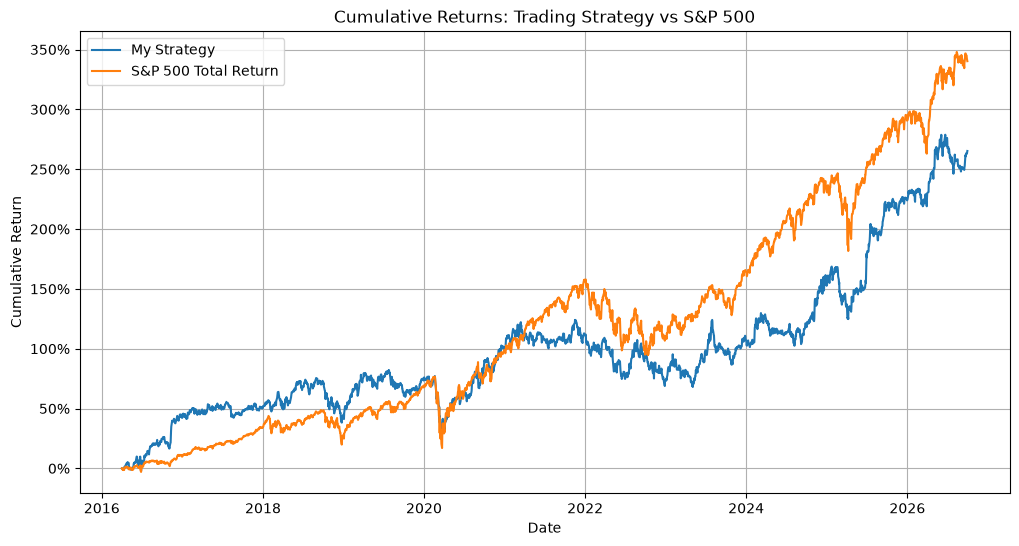

In [75]:
from matplotlib.ticker import PercentFormatter

# calculate cumulative returns for our trading strategy
portfolio_values["cumulative_return"] = (
    portfolio_values["portfolio_value"] / initial_capital - 1)

# calculate cumulative returns for the S&P 500
benchmark_values["cumulative_return"] = (
    benchmark_values["benchmark_value"] / initial_capital - 1)

# create comparison chart
plt.figure(figsize=(12, 6))

# plot our trading strategy
plt.plot(
    portfolio_values["date"],
    portfolio_values["cumulative_return"],
    label="My Strategy")

# plot the S&P 500
plt.plot(
    benchmark_values["date"],
    benchmark_values["cumulative_return"],
    label="S&P 500 Total Return")

# add chart labels
plt.title("Cumulative Returns: Trading Strategy vs S&P 500")
plt.xlabel("Date")
plt.ylabel("Cumulative Return")

# display returns as percentages
plt.gca().yaxis.set_major_formatter(PercentFormatter(1))

# add legend and grid
plt.legend()
plt.grid(True)

plt.show()

# Conclusion

My strategy increased the initial $1 million investment to approximately $3.65 million, an annualized return of 13.13%. However, it underperformed the S&P 500 , which reached approximately $4.40 million with an annualized return of 15.17%. My strategy experienced a slightly smaller maximum drawdown of 31.05% compared with 33.79% for the benchmark, although its Sharpe ratio was lower. This suggests that combining historical momentum with predicted 90 day returns produced positive returns but did not consistently outperform a passive market investment.

One possible limitation is the portfolio's fixed monthly investment budget, which may have left too much capital uninvested during periods of strong market growth. Additionally, several stocks stopped having valid price observations before their scheduled exit dates, requiring indicative valuations rather than confirmed sale proceeds. Future improvements could include investigating these corporate actions and evaluating different capital allocation approaches using a separate development period.

# Required Checks

In [77]:
# verify no borrowing
print("cash never negative:",(portfolio_values["cash"] >= -0.000001).all())

# reconcile cash with transaction history
total_purchases = transactions_df[
    transactions_df["type"] == "BUY"]["amount"].sum()

total_sales = transactions_df[
    transactions_df["type"] == "SELL"]["amount"].sum()

calculated_cash = initial_capital - total_purchases + total_sales

print("cash accounting correct:",
      np.isclose(calculated_cash, cash))

# check the first five purchases and sales
first_buys = transactions_df[
    (transactions_df["date"] == "2016-04-01") &
    (transactions_df["type"] == "BUY")
].copy()

first_sells = transactions_df[
    (transactions_df["date"] == "2016-06-30") &
    (transactions_df["type"] == "SELL") &
    (transactions_df["symbol"].isin(first_buys["symbol"]))
].copy()

# check that holding period was exactly 90 calendar days
holding_days = (
    pd.Timestamp("2016-06-30") -
    pd.Timestamp("2016-04-01")
).days

print("90 day holding period:", holding_days == 90)

print("all first five positions sold:",
      len(first_buys) == 5 and len(first_sells) == 5)

# check that shares purchased equal shares sold
buy_shares = first_buys.set_index("symbol")["shares"].sort_index()
sell_shares = first_sells.set_index("symbol")["shares"].sort_index()

print("purchased shares equal sold shares:",
      buy_shares.index.equals(sell_shares.index) and
      np.allclose(buy_shares, sell_shares))

cash never negative: True
cash accounting correct: True
90 day holding period: True
all first five positions sold: True
purchased shares equal sold shares: True
